# Importation des données 

In [2]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
from sklearn.datasets import fetch_openml
from src.graph import *
freq = fetch_openml(data_id=41214, as_frame=True).frame
sev = fetch_openml(data_id=41215, as_frame=True).frame
print("La première table freq contient les données de " + str(freq.shape[0]) + " polices d'assurance et " + str(freq.shape[1]) + " variables.")
print("La deuxième table sev contient les données de " + str(sev.shape[0]) + " sinistres et " + str(sev.shape[1]) + " variables.")
print(freq.head())
print(sev.head())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
La première table freq contient les données de 678013 polices d'assurance et 12 variables.
La deuxième table sev contient les données de 26639 sinistres et 2 variables.
   IDpol  ClaimNb  Exposure Area  VehPower  VehAge  DrivAge  BonusMalus  \
0    1.0        1      0.10    D         5       0       55          50   
1    3.0        1      0.77    D         5       0       55          50   
2    5.0        1      0.75    B         6       2       52          50   
3   10.0        1      0.09    B         7       0       46          50   
4   11.0        1      0.84    B         7       0       46          50   

  VehBrand     VehGas  Density Region  
0      B12  'Regular'     1217    R82  
1      B12  'Regular'     1217    R82  
2      B12   'Diesel'       54    R22  
3      B12   'Diesel'       76    R72  
4      B12   'Diesel'       76    R72  
     IDpol  ClaimAmount
0     1552       995.20
1  1

### Table `freq` — les contrats (678 013 lignes, 12 variables)
- IDpol : identifiant unique de chaque police.
- ClaimNb : nombre de sinistre survenus sur la période
- Exposure : durée de couverture en années police
- DrivAge : age du conducteur 
- BonusMalus : coefficient de Bonus-Malus francais, allant de 50 à 350 selon la conduite du conducteur
- VehPower : catégorie de puissance du véhicule 
- VehAge : age du véhicule 
- VehBrand : marque anonymisé du véhicule
- VehGas : type de carburant du véhicule 
- Density : densité de la population dans la zone de résidence en hab/km²
- Area : discrétisation de "density", niveau de densité de la zone de résidence
- Region : région administrative française, climat, météo, état des routes ...

### Table `sev` — les sinistres (26 639 lignes, 2 variables)
- IDpol : identifiant de la police concernée par le sinistre
- ClaimAmount : montant du sinistre, en euros.

Avant de commencer a manipuler les données, il est important de constater s'il y a des erreurs dans les tables de données. Par exemple nous allons regarder s'il y a des doublons dans les polices, des temps d'exposition qui depassent 1 an, ou s'il y a des fréquences de sinistres anormalement haute, ce qui traduirait des erreurs de saisies. (Fortement probable sur un jeu de données de cette taille)

In [3]:
# vérification d'éventuelles valeurs manquantes
print(freq.isnull().sum())

IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
dtype: int64


In [4]:
print(freq.dtypes)
print(sev.dtypes)

IDpol          float64
ClaimNb          int64
Exposure       float64
Area          category
VehPower         int64
VehAge           int64
DrivAge          int64
BonusMalus       int64
VehBrand      category
VehGas             str
Density          int64
Region        category
dtype: object
IDpol            int64
ClaimAmount    float64
dtype: object


In [5]:
#Vérification d'éventuelles valeurs dupliquées, notamment sur l'identifiant de police
print("le nombre de polices dupliquées est de", freq['IDpol'].duplicated().sum())

le nombre de polices dupliquées est de 0


In [6]:
print(freq.groupby('Area')['Density'].describe())

         count          mean          std      min      25%      50%      75%  \
Area                                                                            
A     103957.0     27.502852    12.498298      1.0     16.0     27.0     38.0   
B      75459.0     72.582184    14.844165     50.0     59.0     72.0     85.0   
C     191880.0    248.935324   113.739091    100.0    150.0    222.0    335.0   
D     151596.0   1075.898493   398.831083    500.0    725.0   1054.0   1328.0   
E     137167.0   4380.299598  1953.098541   2001.0   3184.0   3744.0   4762.0   
F      17954.0  22014.560878  6387.884636  10008.0  16052.0  27000.0  27000.0   

          max  
Area           
A        50.0  
B       100.0  
C       500.0  
D      1993.0  
E      9850.0  
F     27000.0  


On confirme ici la redondance des features Area et Density, Area étant bien une discrétisation de Density. On remarque cependant que pour la zone F, la médiane, le 3ème quantile valent 27000, soit la valeur maximale de Density, il s'agit surement de zone urbaine très peuplée, comme Paris intra muros par exemple.

In [7]:
# verification de l'intégrité des données

print(freq[['VehPower','VehAge','DrivAge','BonusMalus','Density']].describe())
print("nombre de score bonus/malus en dehors de la legislation : ", (freq['BonusMalus'] > 350).sum(), (freq['BonusMalus'] < 50).sum())
print("nombre de conducteurs avec un âge inférieur à 18 ans : ", (freq['DrivAge'] < 18).sum())

            VehPower         VehAge        DrivAge     BonusMalus  \
count  678013.000000  678013.000000  678013.000000  678013.000000   
mean        6.454631       7.044265      45.499122      59.761502   
std         2.050906       5.666232      14.137444      15.636658   
min         4.000000       0.000000      18.000000      50.000000   
25%         5.000000       2.000000      34.000000      50.000000   
50%         6.000000       6.000000      44.000000      50.000000   
75%         7.000000      11.000000      55.000000      64.000000   
max        15.000000     100.000000     100.000000     230.000000   

             Density  
count  678013.000000  
mean     1792.422405  
std      3958.646564  
min         1.000000  
25%        92.000000  
50%       393.000000  
75%      1658.000000  
max     27000.000000  
nombre de score bonus/malus en dehors de la legislation :  0 0
nombre de conducteurs avec un âge inférieur à 18 ans :  0


Les bornes réglementaire de bonus-malus française (50-350) sont respectées et aucun conducteur n'a moins de 18 ans.

Cependant on constate une erreur sur la feature VehAge dont le maximum est à 100, ce qui pose question pour l'age d'une voiture. On va aussi s'interesser au 100 de DrivAge voir si c'est une valeur normal ou un plafond de la table freq. Le reste des variables ne supposent aucun problème/

In [8]:
print((freq['VehAge'] > 30).sum(), (freq['VehAge'] >= 100).sum())
print((freq['DrivAge'] > 90).sum(), (freq['DrivAge'] >= 100).sum())
print(freq['VehAge'].value_counts().sort_index().tail(15))
print(freq['DrivAge'].value_counts().sort_index().tail(15))


1116 25
401 3
VehAge
68      2
69      4
70      3
71      1
76      1
78      1
79      1
80      3
81      3
82      1
83      2
84      1
85      1
99     23
100    25
Name: count, dtype: int64
DrivAge
86     319
87     280
88     229
89     198
90     167
91     121
92      66
93      55
94      32
95      24
96      15
97      10
98       5
99      70
100      3
Name: count, dtype: int64


In [9]:
print(freq['DrivAge'].value_counts().sort_index().loc[92:100])

DrivAge
92     66
93     55
94     32
95     24
96     15
97     10
98      5
99     70
100     3
Name: count, dtype: int64


Le nombre de véhicule à age élevé decroit normalement jusqu'à 85, puis plus rien jusqu'à 98, et brusquement 48 véhicules entre 99 et 100, impossible, il s'agit surement là d'une valeur code pour signaler un "âge inconnu". De plus tous les autres véhicules au dessus de 30 ans ne ont pas forcément abérrants, mais pour rester dans un seuil raisonnable de travail, nous allons donc les fixer à 30 ans. Sans quoi les effectifs deviennent trop faibles pour estimer quoi que ce soit de fiable.

De même içi la décroissance est régulière et plausible jusqu'à 99 ans ou il se produit un pic anormale, il doit aussi s'agir d'une valeur sentinelle. Nous allons donc plafonner les ages à 90 ans.

In [10]:
freq['VehAge'] = freq['VehAge'].clip(upper=30)
freq['DrivAge'] = freq['DrivAge'].clip(upper=90)

In [11]:

print(freq['VehGas'].describe())

#retrait des apostrophes dans la variable VehGas
freq['VehGas'] = freq['VehGas'].str.strip("'")

count        678013
unique            2
top       'Regular'
freq         345877
Name: VehGas, dtype: object


In [12]:
print(freq['Exposure'].describe())
print("Nombre de polices dont l'exposition est supérieur à 1 : ", (freq['Exposure'] > 1).sum())

count    678013.000000
mean          0.528750
std           0.364442
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64
Nombre de polices dont l'exposition est supérieur à 1 :  1224


Le fait que certaines exposition dépasse un an (le cas pour 1224 contrats) est une anomalie car on est sur un jeu de données qui est censé contenir des contrats annuels.

On ramène les temps d'exposition des contrats dépassant une durée de 1 an à 1 car il s'agit surement là d'une anomalie et de toute façon leur impact sera négligeable. Seulement 1224 sur 678 000 ...

In [13]:

freq['Exposure'] = freq['Exposure'].clip(upper=1)

On vérifie maintenant s'il n'y a pas des valeurs de ClaimNb qui seraient incohérentes.

In [14]:
print((freq['ClaimNb']).value_counts().sort_index(ascending=False))

ClaimNb
16         1
11         3
9          1
8          1
6          1
5          2
4          7
3         82
2       1784
1      32178
0     643953
Name: count, dtype: int64


La distribution de ClaimNb décroit régulièrement jusqu'à 4, puis devient incohérente : 3 à 11 alors qu'il n'y en a pas plus de 2 de 5 à 9. Une loi de probabilité de comptage n'a pas de telle distribution, il s'agit donc surement d'un artefact.

In [15]:
freq.loc[freq['ClaimNb'] >= 4, ['IDpol', 'ClaimNb', 'Exposure']]


,IDpol,ClaimNb,Exposure
551,1147.0,4,0.08
6539,19471.0,11,1.00
9136,24495.0,4,1.00
25347,54009.0,4,0.56
46470,93954.0,5,1.00
304484,2216294.0,6,0.33
320764,2239279.0,8,0.41
321248,2241683.0,16,0.33
321512,2248174.0,9,0.08
344616,2277762.0,5,0.08


Regarder directement les polices ayant plus un ClaimNb de 4 ou plus le confirme, la pluspart ont des périodes d'exposition courtes : 16 sinistres sur 4 mois, cela dépasse toute réalité de souscription, un tel client serait sans doute résilié.



J'ai d'abord essayé içi d'appliquer un critère de discrimination sur la fréquence implicite des sinistres par police. En effet un raisonnement simple pourrait être que si on a une fréquence implicite très élevé, il s'agit surement d'une anomalie. Or il est, au vu du résultat ci dessous mal adapté car il pénalise les exposition courtes avec peu de sinistres tout en épargnant potentiellement des nombres anormalement grand de sinistre mais sur une longue exposition. 

In [16]:
extremes = freq.loc[freq['ClaimNb'] >= 4].copy()
extremes['freq_implicite'] = extremes['ClaimNb'] / extremes['Exposure']
extremes[['ClaimNb', 'Exposure', 'freq_implicite']].sort_values('freq_implicite', ascending=False)

,ClaimNb,Exposure,freq_implicite
488270,11,0.07,157.142857
487268,11,0.08,137.500000
321512,9,0.08,112.500000
344616,5,0.08,62.500000
551,4,0.08,50.000000
321248,16,0.33,48.484848
501990,4,0.10,40.000000
320764,8,0.41,19.512195
304484,6,0.33,18.181818
364437,4,0.27,14.814815


Nous allons donc ramener toutes ces valeurs à 4, elles représentent 16 polices sur 678 013 soit 0.002%, l'écart que ce changement produira sur la fréquence annualisé du portefeuille est négligeable.

In [17]:
freq['ClaimNb']  = freq['ClaimNb'].clip(upper=4)

In [18]:
print((freq['ClaimNb']).value_counts().sort_index())

ClaimNb
0    643953
1     32178
2      1784
3        82
4        16
Name: count, dtype: int64


In [19]:
#vérification du nombre de sinistre totale de sinistres déclaré et du nombre de ligne dans la table sev
total_claims = freq["ClaimNb"].sum()
print("Le nombre total de sinistres déclarés est de " + str(total_claims) + " et le nombre de lignes dans la table sev est de " + str(sev.shape[0]) + ".")

Le nombre total de sinistres déclarés est de 36056 et le nombre de lignes dans la table sev est de 26639.


In [20]:
# nb_claims_sev regroupe le nombre de sinistres par police dans la table sev, ce qui permet de comparer avec le comptage de sinistres dans la table freq
nb_claims_sev = sev.groupby('IDpol').size().rename('nb_lignes_sev')

#on regroupe ensuite les deux tables freq et nb_claims_sev pour comparer le comptage de sinistres entre les deux tables
comparaison = freq.merge(nb_claims_sev, how='left', left_on='IDpol', right_index=True)

#les polices n'ayant jamais eu de sinistres dans les deux tables auront une valeur NaN dans la colonne nb_lignes_sev, on remplace donc ces valeurs par 0 et on convertit la colonne en int
comparaison['nb_lignes_sev'] = comparaison['nb_lignes_sev'].fillna(0).astype(int)


#on regroupe dans 'différents' les polices pour lesquelles le comptage de sinistres est différent entre freq et sev
differents = comparaison.loc[comparaison['ClaimNb'] != comparaison['nb_lignes_sev']]
print("Nombre de polices pour lesquelles le comptage de sinistres est différent entre freq et sev :", differents.shape[0])
print("Nombre de sinistres déclarés par ces polices : ", differents["ClaimNb"].sum())
print("Nombre de sinistres chiffrés payé par ces polices: ", differents["nb_lignes_sev"].sum())

Nombre de polices pour lesquelles le comptage de sinistres est différent entre freq et sev : 9125
Nombre de sinistres déclarés par ces polices :  9684
Nombre de sinistres chiffrés payé par ces polices:  72


In [21]:
#On ajoute dans comparaison une colonne manquant à variable booléenne qui indique si une police a des sinistres déclarés mais auncun de sinistres chiffrés
comparaison["manquant"] = (comparaison["ClaimNb"] > 0) & (comparaison["nb_lignes_sev"] == 0)
print("Nombre de polices ayant déclarés au moins 1 sinistre mais aucun de chiffrés : ", comparaison["manquant"].sum())

#On regarde aussi le nombre de polices pour lesquelles il manque des sinistres chiffrés par rapport au nombre de polices ayant déclarés des sinistres
intermediaire = differents.loc[differents["nb_lignes_sev"] > 0]
print("Nombre de polices dans le cas intermediaire ou il y a des sinistres déclarés et quelque uns sont chiffrés mais pas la totalité : ", intermediaire.shape[0])

# On peut maintenant comparer les profils des polices pour lesquels il manque des sinistres chiffrés avec ceux pour lesquels il n'en manque pas pour voir si l'on peut identifier un shéma.
profils = freq.merge(comparaison[["IDpol", "manquant"]], on='IDpol')
profils = profils.loc[profils["ClaimNb"] > 0]
print(profils.groupby('manquant')[['Exposure', 'DrivAge', 'BonusMalus']].mean())
print(profils.groupby('manquant').size())

Nombre de polices ayant déclarés au moins 1 sinistre mais aucun de chiffrés :  9116
Nombre de polices dans le cas intermediaire ou il y a des sinistres déclarés et quelque uns sont chiffrés mais pas la totalité :  9
          Exposure    DrivAge  BonusMalus
manquant                                 
False     0.692369  45.137428   64.930164
True      0.505206  49.256143   58.083699
manquant
False    24944
True      9116
dtype: int64


**Incohérence entre les deux tables.** 36 056 sinistres sont déclarés dans freq
contre 26 639 lignes dans sev, soit environ 9 600 sinistres sans montant
associé, répartis sur 9 116 polices.

Le fait que seulement 9 polices présentent une situation intermédiaire, certains sinistres chiffrés et d'autres non exclut la possibilité qu'une partie massive des sinistres ne soient pas encore chiffrés ou payée.

De plus, après examen des trois variables les plus parlante sur les profils de ces polices, on constate un écart de moyenne conséquent. En effet la moyenne d'exposition passe de 0.69 à 0.50, celle d'age de 45 à 49 ans et celle de bonus / malus de 65 à 58.

Cela ne peut pas être du bruit sur plus de 9000 observation, ces différences concernent des conducteurs plus agés avec de meilleirs coefficients et un durée d'exposition plus courte, il s'agit donc surement là d'un segment de portefeuille identifiable, et ces polices viennent surement d'une autre machine ou d'un autre portefeuille que les autres et dont les données de sinistres n'ont pas été transférées.

Pour confirmer cette hypothèse, on peut regarder si les IDpol sont segmentés aussi, car il s'agit d'une attribution automatique, et cela montrerait que toutes ces polices ont été extraitent en même temps d'une autre base de données et dont les sinistres correspondant ont été oubliés.

In [22]:
print(profils.groupby('manquant')['IDpol'].describe())

            count          mean           std    min        25%        50%  \
manquant                                                                     
False     24944.0  2.262558e+06  1.578475e+06  139.0  1082689.5  2130098.5   
True       9116.0  1.657512e+04  1.166286e+05    1.0     4852.5    10292.5   

                 75%        max  
manquant                         
False     3178541.75  6113971.0  
True        20382.25  5068217.0  


L'examen des plages des identifiants le confirme, 75% des polices sans montant ont un IDpol inférieur à 20384 et un médian à 10293 alors que les polices sans problèmes sont étalée de 139 à plus de 6 millions.

On peut donc dire que les deux populations occupent des plages d'identifiants pratiquement disjointes, cette différence vient donc d'un problème d'extraction et non un phénomène assurantiel.

**Conséquence.** Le modèle de sévérité ne pourra être estimé que sur les sinistres chiffrés, soit environ 74 % du total. Ce sous-ensemble n'est pas représentatif du portefeuille : les polices exclues présentent une exposition moyenne plus courte (0,51 contre 0,69 année), des conducteurs plus âgés (49 contre 45 ans) et de meilleurs coefficients bonus-malus (58 contre 65). Ces variables étant des prédicteur du modèle, un biais d'estimation est possible.

Les polices concernées disposent d'un 'ClaimNb' et d'une 'Exposure' valide, elle seront donc conservées dans la base de frequence car elles apportent une réelle information sur la fréquence. Les exclure reviendrait simplement à effacer une part non négligeable de polices sinistrées tout en conservant l'ensemble des polices non sinistrées.

La restriction s'opérera uniquement et automatiquement lors de la construction de la base de sévérité, en effet une police sans montant de sinistres n'aura simplement rien à apporter à ce modèle. Mais ce constat permet d'être au courant du manque d'une partie non négligeable des données qui auraient étés utiles à l'entrainement de ce modèle.

In [23]:
print((sev["ClaimAmount"] <= 1).sum())
print(sev["ClaimAmount"].quantile([0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))
print(sev['ClaimAmount'].value_counts().head(10))

1
0.01       40.0314
0.10      197.3360
0.25      686.8100
0.50     1172.0000
0.75     1228.0800
0.90     2799.0720
0.99    16793.7044
Name: ClaimAmount, dtype: float64
ClaimAmount
1204.00    4792
1128.12    3056
1172.00    2072
1128.00     831
602.00      433
1320.00     175
556.14      155
586.00      104
1500.00     103
564.06       94
Name: count, dtype: int64


on remarque que certaines valeurs reveinnent beaucoup dans les couts d'un sinistre. Surement un montant de provision standard demandé par l'assureur à l'ouverture d'un dossier de sinistre.

Il est très important de le noter car cela aura une incidence sur la suite car ces montants etants vraissemblablement standards et automatiques, il ne dependent pas a premiere vue des caractéristiques de l'assuré, c'est un forfait.

Une fois toutes les erreurs corrgiées et remaques faites sur le dataset, nous pouvons calculer la fréquence annualisée de sinistre.

In [24]:
print("la fréquence annualisée de sinistres : ", freq['ClaimNb'].sum() / freq['Exposure'].sum())

la fréquence annualisée de sinistres :  0.1006138781922095


Index(['exposition', 'sinistres'], dtype='str')
Index(['exposition', 'sinistres'], dtype='str')
Index(['exposition', 'sinistres'], dtype='str')
Index(['exposition', 'sinistres'], dtype='str')
Index(['exposition', 'sinistres'], dtype='str')
Index(['exposition', 'sinistres'], dtype='str')
Index(['exposition', 'sinistres'], dtype='str')
Index(['exposition', 'sinistres'], dtype='str')
Index(['exposition', 'sinistres'], dtype='str')


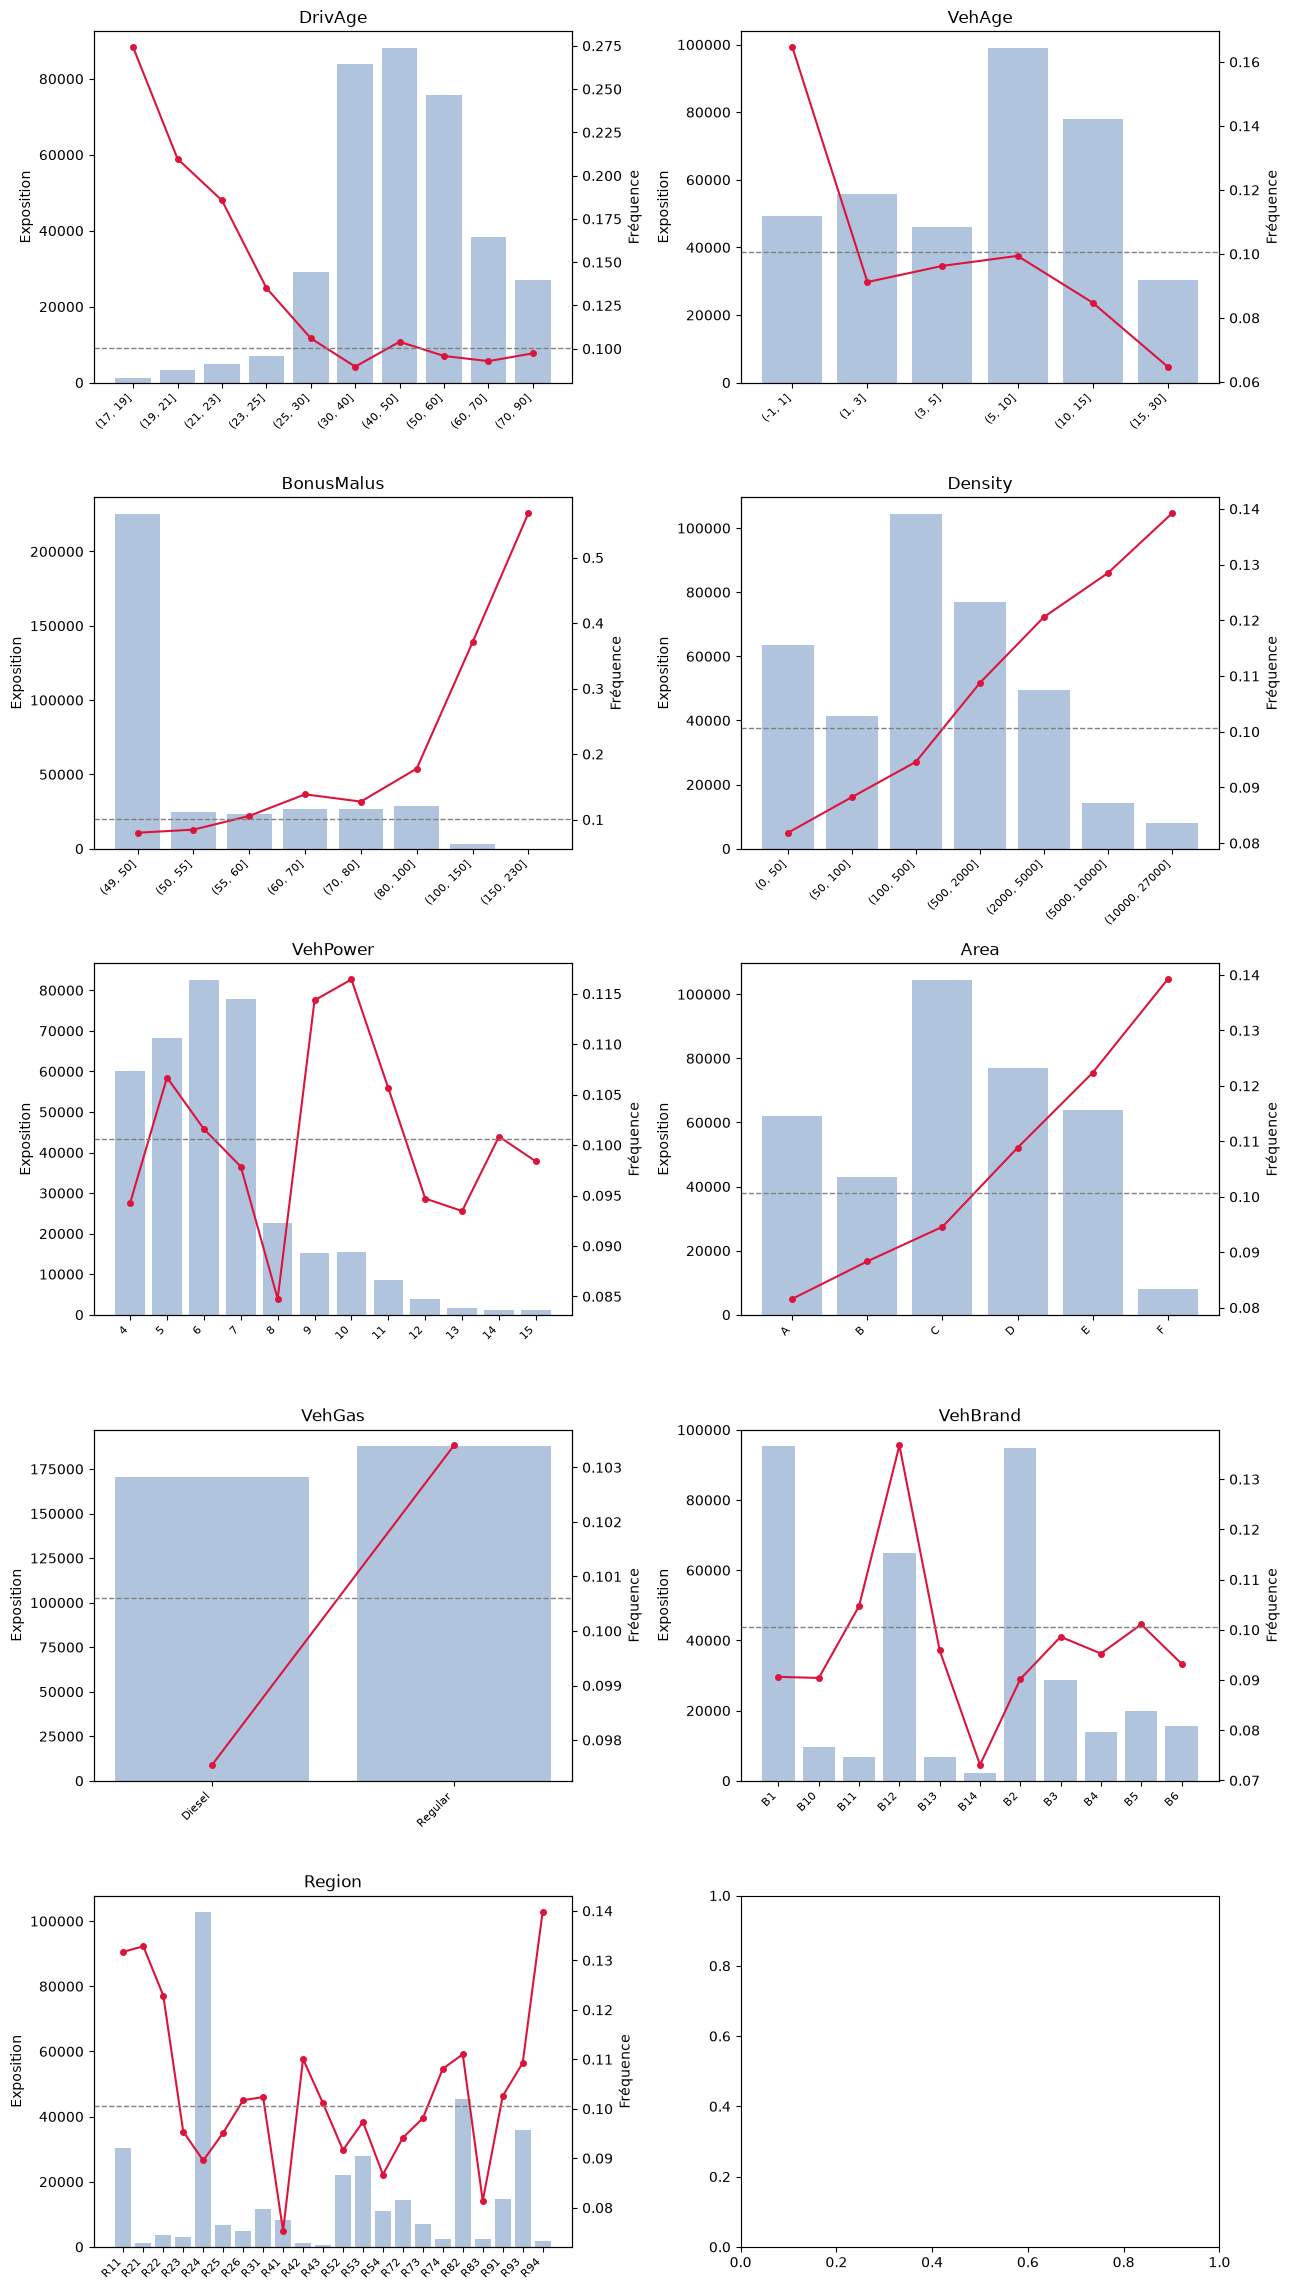

In [35]:
variables = {
    'DrivAge':    [17,19,21,23,25,30,40,50,60,70,90],
    'VehAge':     [-1,1,3,5,10,15,30],
    'BonusMalus': [49,50,55,60,70,80,100,150,230],
    'Density':    [0,50,100,500,2000,5000,10000,27000],
    'VehPower':   None,
    'Area':       None,
    'VehGas':     None,
    'VehBrand':   None,
    'Region':     None,
}

fig, axes = plt.subplots(5, 2, figsize=(13, 23))

for ax, (col, bins) in zip(axes.flat, variables.items()):
    plot_freq_par_groupe(freq, col, bins=bins, ax=ax)

plt.tight_layout()
plt.show()

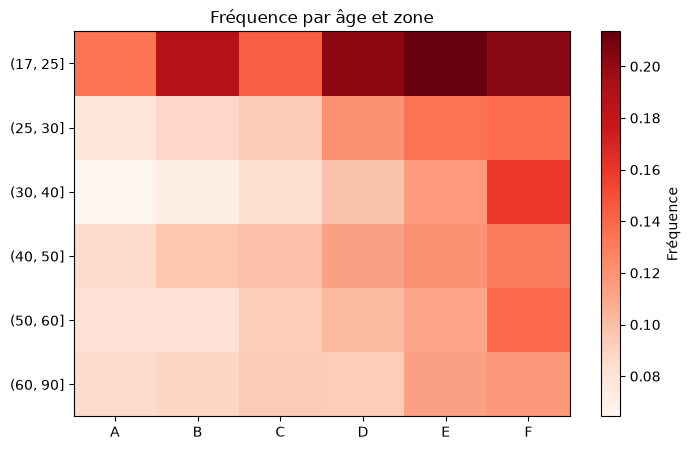

In [36]:
d = freq.copy()
d['age_grp'] = pd.cut(d['DrivAge'], bins=[17,25,30,40,50,60,90])
piv = d.groupby(['age_grp','Area'], observed=True).agg(
    e=('Exposure','sum'), n=('ClaimNb','sum'))
piv['f'] = piv['n']/piv['e']
piv = piv['f'].unstack()

plt.figure(figsize=(8,5))
plt.imshow(piv, aspect='auto', cmap='Reds')
plt.colorbar(label='Fréquence')
plt.xticks(range(len(piv.columns)), piv.columns)
plt.yticks(range(len(piv.index)), [str(i) for i in piv.index])
plt.title("Fréquence par âge et zone")
plt.show()